# La Amazonía, entre el fuego y la sequía

**810 millones de toneladas de carbono.** Es lo que la Amazonía soltó a la atmósfera en 2024, el peor año de una serie de 15 reconstruida con vuelos de avioneta. ¿Sigue siendo la selva una esponja de carbono?

**Paper:** Gatti et al. (2026). *Amazon carbon emissions driven by human actions amplified by droughts*. **Nature**.
**DOI:** [10.1038/s41586-026-11168-1](https://doi.org/10.1038/s41586-026-11168-1)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ciencia-a-Mordiscos/lab/blob/main/papers/2026-10-21-amazonia-emisiones-carbono-incendios-sequia/notebook.ipynb)

**Video:** Pendiente

## ¿Qué midieron?

Entre 2010 y 2024, el equipo voló una avioneta en espiral descendente sobre cuatro puntos de la Amazonía brasileña y llenó frascos de aire desde unos 4.400 m hasta cerca del suelo. Comparando ese aire con el que entra desde el Atlántico (el fondo, *background*), calcularon cuánto carbono gana el aire al cruzar la selva. De ahí salen tres cifras, en PgC/año (mil millones de toneladas de carbono por año):

- **Balance total**: todo lo que la región suelta menos lo que absorbe. Positivo = fuente.
- **Fuego**: el carbono atribuido a la quema a partir del monóxido de carbono (CO).
- **Bosque** (intercambio neto del bioma, *NBE*): negativo = la selva absorbe más de lo que respira.

El balance total es la suma de fuego y bosque.

In [1]:
# ══════════════════════════════════════════════════════════════
# Configuración — modifica estos valores para explorar
# ══════════════════════════════════════════════════════════════
ANIO_DESTACADO = 2024        # año que se resalta en las gráficas (2010–2024)
REGION = 'ALF'               # región para la celda experimental: 'ALF', 'RBA', 'SAN' o 'TTC'
BANDA_MIN, BANDA_MAX = 1500, 4000   # franja de altura (m) para comparar el exceso de CO₂
FUENTE = 'Fuente: Gatti et al. (2026), Nature | Datos: Extended Data Table 2 y PANGAEA (doi:10.1594/PANGAEA.988417)'
COLOR_DATOS = '#2563EB'
COLOR_ALERTA = '#DC2626'
COLOR_REFERENCIA = '#D97706'
COLOR_BOSQUE = '#059669'
COLOR_GRUPO = {1: '#2563EB', 2: '#7C3AED', 3: '#D97706'}
NOMBRE_GRUPO = {1: 'Grupo 1\nhúmedos, poca\nactividad humana', 2: 'Grupo 2\ndeforestación\nalta',
                3: 'Grupo 3\nsecos y\ncálidos'}

import os, re, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import stats

BASE = 'https://raw.githubusercontent.com/Ciencia-a-Mordiscos/lab/main/papers/2026-10-21-amazonia-emisiones-carbono-incendios-sequia'
ARCHIVOS = ['amazonia_anual.csv', 'regiones_anual.csv', 'perfiles_dco2.csv', 'perfil_vertical_por_grupo.csv']
os.makedirs('datos', exist_ok=True)
os.makedirs('figuras', exist_ok=True)
for a in ARCHIVOS:
    if not os.path.exists(f'datos/{a}'):
        urllib.request.urlretrieve(f'{BASE}/datos/{a}', f'datos/{a}')

style_file = '../../cam.mplstyle'
if not os.path.exists(style_file):
    style_file = '/tmp/cam.mplstyle'
    if not os.path.exists(style_file):
        urllib.request.urlretrieve('https://raw.githubusercontent.com/Ciencia-a-Mordiscos/lab/main/cam.mplstyle', style_file)
plt.style.use(style_file)

# Números en formato español: coma decimal, punto de miles ({n:_}), signo menos tipográfico
def es(x):
    s = str(x)
    s = re.sub(r'(?<=\d)\.(?=\d)', ',', s)
    s = re.sub(r'(?<![\w,])-(?=\d)', '−', s)
    return s.replace('_', '.')

def pr(*a):
    print(*[es(x) for x in a])

def fp(p):
    return 'p < 0,001' if p < 0.001 else 'p = ' + es(f'{p:.3f}')

def cohen_d(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (b.mean() - a.mean()) / sp

COMA = FuncFormatter(lambda v, _: es(f'{v:g}'))

anual = pd.read_csv('datos/amazonia_anual.csv')          # Extended Data Table 2, Amazonía completa
regiones = pd.read_csv('datos/regiones_anual.csv')       # Extended Data Table 2, cuatro regiones
perfiles = pd.read_csv('datos/perfiles_dco2.csv')        # PANGAEA: media de (observado − fondo) por perfil
vertical = pd.read_csv('datos/perfil_vertical_por_grupo.csv')  # PANGAEA: media por banda de 500 m y grupo

tcf, fcf, nbe = anual.tcf_pgc_yr, anual.fcf_pgc_yr, anual.nbe_pgc_yr
q1, q3 = np.percentile(tcf, [25, 75])
pr(f'Serie anual: {len(anual)} años ({anual.anio.min()}–{anual.anio.max()})')
pr(f'Balance total medio: {tcf.mean():.2f} PgC/año · mediana {tcf.median():.2f} (IQR {q1:.3f}–{q3:.3f})')
pr(f'Desviación estándar del balance entre años: {tcf.std():.2f} PgC/año')
pr(f'Fuego medio: {fcf.mean():.2f} PgC/año · bosque medio: {nbe.mean():.2f} PgC/año')
pr(f'Fuego medio − balance medio: {fcf.mean() - tcf.mean():+.2f} PgC/año')
pr(f'Perfiles de avión (PANGAEA): {len(perfiles):_} perfiles, {perfiles.n_muestras.sum():_} muestras de aire, '
   f'{perfiles.year.min()}–{perfiles.year.max()}')

Serie anual: 15 años (2010–2024)
Balance total medio: 0,32 PgC/año · mediana 0,32 (IQR 0,135–0,515)
Desviación estándar del balance entre años: 0,25 PgC/año
Fuego medio: 0,40 PgC/año · bosque medio: −0,08 PgC/año
Fuego medio − balance medio: +0,08 PgC/año
Perfiles de avión (PANGAEA): 948 perfiles, 9.178 muestras de aire, 2010–2024


Aquí está.

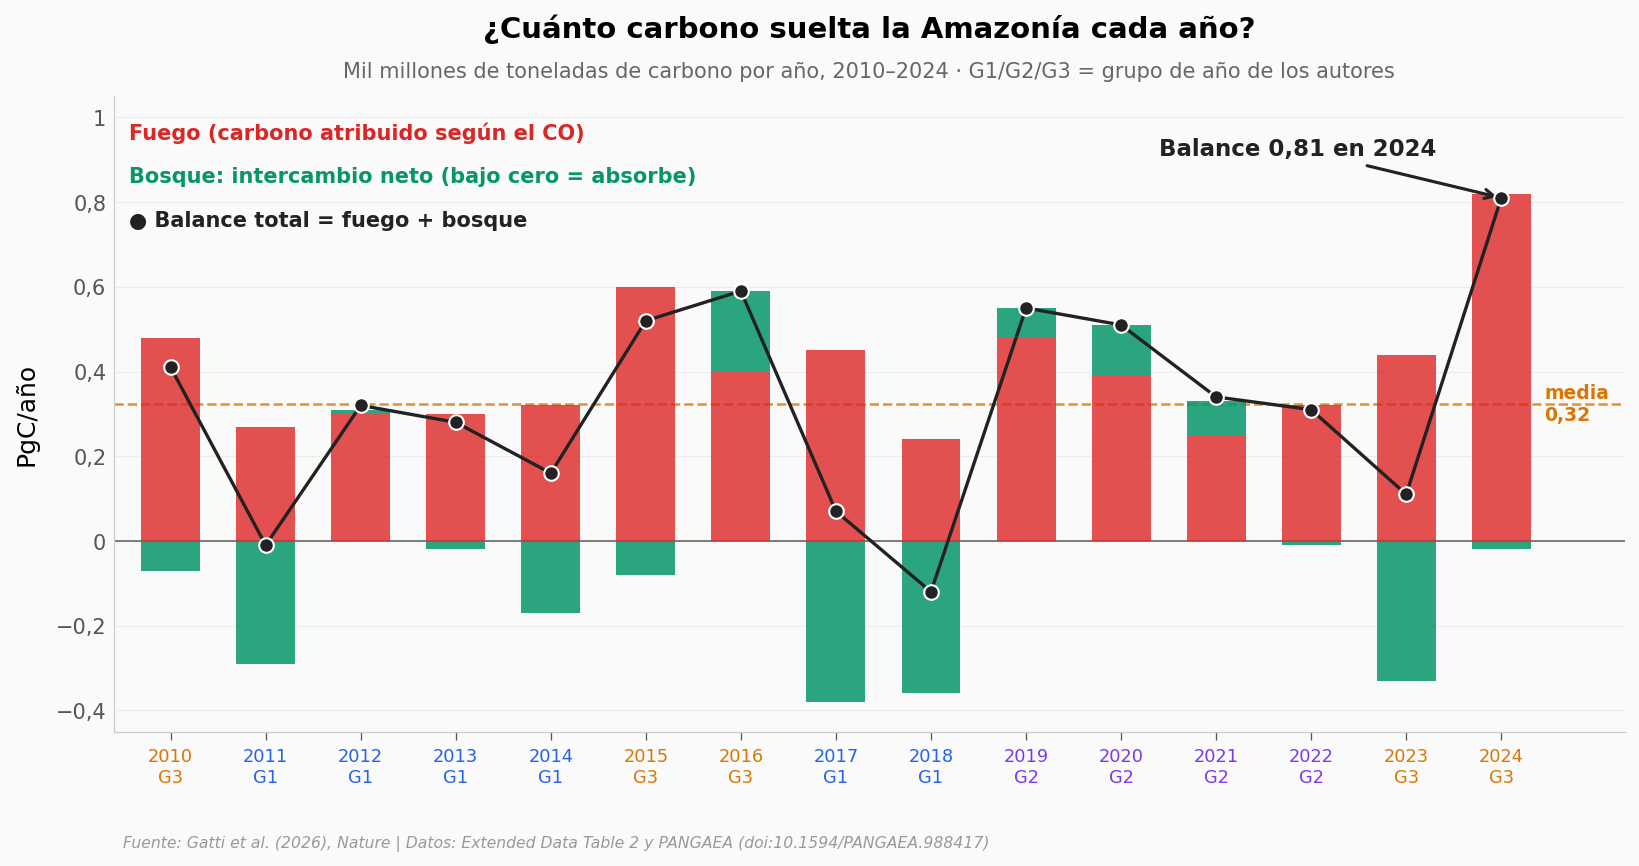

Años con balance > 0 (fuente): 13 de 15
Años con bosque < 0 (absorbe neto): 10 de 15
Años en que el fuego supera al balance total: 10 de 15
2024: balance 0,81 · fuego 0,82 · bosque −0,02 PgC/año
2024: área quemada 155.413 km², +105 % sobre la media de 15 años
Tendencia con el año (balance): ρ = 0,22, p = 0,44 (n = 15)
Tendencia con el año (bosque): ρ = 0,16, p = 0,58 (n = 15)


In [2]:
fig, ax = plt.subplots(figsize=(13, 5.5))
x = anual.anio.values
ax.bar(x, fcf, width=0.62, color=COLOR_ALERTA, alpha=0.8, zorder=3)
# el bosque se apila encima del fuego si emite, y cuelga bajo cero si absorbe
ax.bar(x, nbe, width=0.62, bottom=np.where(nbe > 0, fcf, 0), color=COLOR_BOSQUE, alpha=0.85, zorder=3)
ax.plot(x, tcf, color='#222222', marker='o', ms=7, lw=1.6, markeredgecolor='white', zorder=5)
ax.axhline(0, color='#666666', lw=0.8, zorder=2)
ax.axhline(tcf.mean(), color=COLOR_REFERENCIA, ls='--', lw=1.2, alpha=0.8, zorder=2)
ax.text(x.max() + 0.45, tcf.mean(), 'media\n' + es(f'{tcf.mean():.2f}'), fontsize=9,
        color=COLOR_REFERENCIA, va='center', fontweight='bold')

fila = anual[anual.anio == ANIO_DESTACADO].iloc[0]
ax.annotate('Balance ' + es(f'{fila.tcf_pgc_yr:.2f}') + f' en {ANIO_DESTACADO}',
            xy=(ANIO_DESTACADO, fila.tcf_pgc_yr), xytext=(ANIO_DESTACADO - 3.6, fila.tcf_pgc_yr + 0.1),
            fontsize=11, fontweight='bold', color='#222222',
            arrowprops=dict(arrowstyle='->', color='#222222', lw=1.5))

ax.text(0.01, 0.96, 'Fuego (carbono atribuido según el CO)', transform=ax.transAxes,
        fontsize=10, color=COLOR_ALERTA, fontweight='bold', va='top')
ax.text(0.01, 0.89, 'Bosque: intercambio neto (bajo cero = absorbe)', transform=ax.transAxes,
        fontsize=10, color=COLOR_BOSQUE, fontweight='bold', va='top')
ax.text(0.01, 0.82, '● Balance total = fuego + bosque', transform=ax.transAxes,
        fontsize=10, color='#222222', fontweight='bold', va='top')

ax.set_xticks(x)
ax.set_xticklabels([f'{a}\nG{g}' for a, g in zip(anual.anio, anual.grupo)], fontsize=8.5)
for tick, g in zip(ax.get_xticklabels(), anual.grupo):
    tick.set_color(COLOR_GRUPO[g])
ax.set_xlim(x.min() - 0.6, x.max() + 1.3)
ax.set_ylim(-0.45, 1.05)
ax.yaxis.set_major_formatter(COMA)
ax.set_ylabel('PgC/año')
ax.set_title('¿Cuánto carbono suelta la Amazonía cada año?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'Mil millones de toneladas de carbono por año, 2010–2024 · G1/G2/G3 = grupo de año de los autores',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/balance_anual.png', dpi=200, bbox_inches='tight')
plt.show()

pr(f'Años con balance > 0 (fuente): {(tcf > 0).sum()} de {len(tcf)}')
pr(f'Años con bosque < 0 (absorbe neto): {(nbe < 0).sum()} de {len(nbe)}')
pr(f'Años en que el fuego supera al balance total: {(fcf > tcf).sum()} de {len(tcf)}')
pr(f'{ANIO_DESTACADO}: balance {fila.tcf_pgc_yr:.2f} · fuego {fila.fcf_pgc_yr:.2f} · bosque {fila.nbe_pgc_yr:.2f} PgC/año')
pr(f'{ANIO_DESTACADO}: área quemada {int(fila.area_quemada_km2):_} km², '
   f'{100 * (fila.area_quemada_km2 / anual.area_quemada_km2.mean() - 1):+.0f} % sobre la media de 15 años')
for col, nombre in [('tcf_pgc_yr', 'balance'), ('nbe_pgc_yr', 'bosque')]:
    r, p = stats.spearmanr(anual.anio, anual[col])
    pr(f'Tendencia con el año ({nombre}): ρ = {r:.2f}, p = {p:.2f} (n = {len(anual)})')

Lo que llama la atención: el balance total quedó por encima de cero en 13 de 15 años. En su conjunto, la Amazonía fue fuente neta de carbono durante casi toda la serie.

La selva sí trabaja: en 10 de 15 años su intercambio neto fue negativo, es decir, absorbió más de lo que respiró. Pero no alcanza. El carbono atribuido al fuego promedia 0,40 PgC/año, 0,08 más que el balance total medio de 0,32 PgC/año: la absorción del bosque compensa una parte de la quema, no toda.

Y 2024 rompe la escala: balance de 0,81 PgC/año, con el fuego en 0,82 y un área quemada un 105 % mayor que la media de los 15 años.

⚠️ Dos cautelas. El fuego no se mide directamente: se deduce del CO con un cociente CO₂:CO. Y el «± 0,08» del abstract es la incertidumbre del cálculo (*Monte Carlo*), no la variación entre años, que es mucho mayor: la desviación estándar del balance entre años es 0,25 PgC/año.

¿Va a peor año tras año? Con 15 puntos, la serie no lo muestra como tendencia: ni el balance (ρ = 0,22, p = 0,44) ni el bosque (ρ = 0,16, p = 0,58; n = 15 años) suben de forma consistente con el año.

## Tres tipos de año

Si no hay una rampa limpia, ¿qué separa a los años malos de los buenos? Los autores agruparon los 15 años en tres tipos con un algoritmo de agrupamiento (*k-means*) que mezcla clima, fuego, deforestación y el propio balance de carbono: años húmedos con poca actividad humana (grupo 1), años de deforestación alta (grupo 2, 2019–2022) y años secos y cálidos, como los de El Niño (grupo 3).

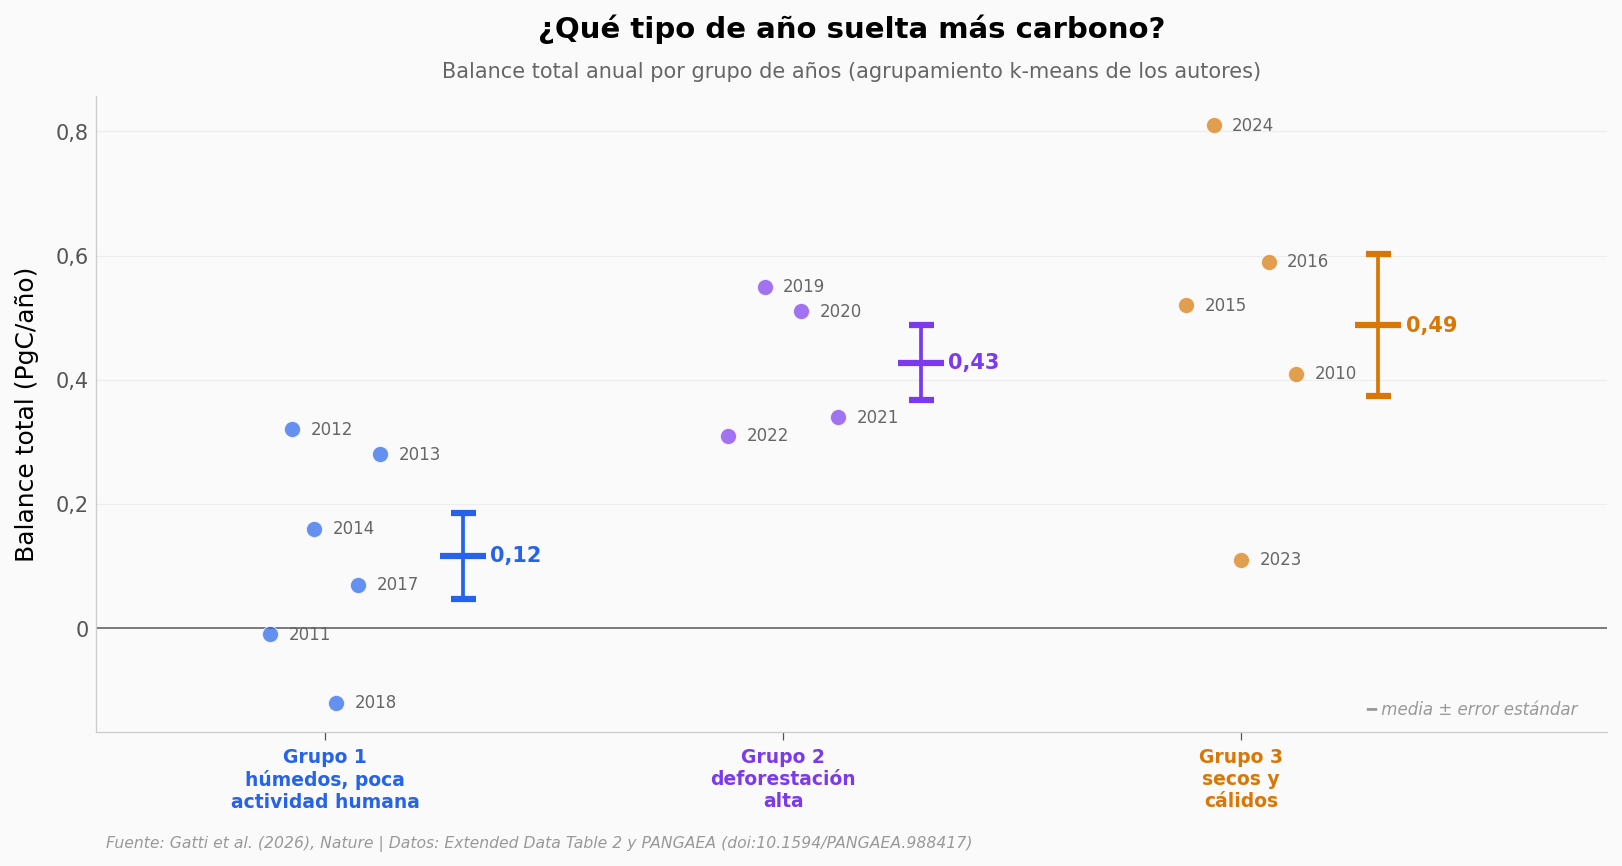

Media por grupo                G1 (n=6)     G2 (n=4)     G3 (n=5)
Balance (PgC/año)                 0,117        0,427        0,488
Fuego (PgC/año)                   0,313        0,360        0,548
Bosque (PgC/año)                 −0,202        0,065       −0,062
Deforestación (km²/año)           6.389       12.580        7.812
Área quemada (km²)               55.115       68.748      105.819
Lluvia anual (mm)                 2.413        2.280        2.105
Lluvia ago–oct (mm)                 135          132          111
T ago–oct (°C)                    26,17        26,30        26,94

Balance: G2 − G1 = +0,31 · G3 − G1 = +0,37 PgC/año
Deforestación G2 vs G1: +97 % · G3 vs G1: +22 %
Área quemada G2 vs G1: +25 % · G3 vs G1: +92 %
Lluvia anual G3 − G1: −308 mm · T ago–oct G3 − G1: +0,77 °C
Grupo 1: el bosque compensa el 64 % del carbono del fuego

Comparaciones de balance (Mann-Whitney; d de Cohen):
  G1 vs G2: p = 0,019, d = 2,03 (n = 6 y 4)
  G1 vs G3: p = 0,030, d = 1,74 (n = 6 y 5)

In [3]:
fig, ax = plt.subplots(figsize=(13, 5.5))
np.random.seed(42)
positions = [0, 1, 2]
grupos = {g: anual[anual.grupo == g] for g in (1, 2, 3)}
for pos, g in zip(positions, grupos):
    sub = grupos[g]
    vals = sub.tcf_pgc_yr.values
    n = len(vals)
    x_strip = np.linspace(pos - 0.12, pos + 0.12, n)
    np.random.shuffle(x_strip)
    ax.scatter(x_strip, vals, color=COLOR_GRUPO[g], s=60, alpha=0.7, edgecolors='white', linewidths=0.5, zorder=5)
    for xs, v, a in zip(x_strip, vals, sub.anio):
        ax.text(xs + 0.04, v, str(a), fontsize=8, color='#666666', va='center')
    sem = vals.std(ddof=1) / np.sqrt(n)
    ax.errorbar(pos + 0.3, vals.mean(), yerr=sem, fmt='_', color=COLOR_GRUPO[g], markersize=22,
                markeredgewidth=3, capsize=6, capthick=1.5, zorder=6)
    ax.text(pos + 0.36, vals.mean(), es(f'{vals.mean():.2f}'), fontsize=10, color=COLOR_GRUPO[g],
            fontweight='bold', va='center')
ax.axhline(0, color='#666666', lw=0.8)
ax.set_xticks(positions)
ax.set_xticklabels([NOMBRE_GRUPO[g] for g in grupos], fontsize=9, fontweight='bold')
for tick, g in zip(ax.get_xticklabels(), grupos):
    tick.set_color(COLOR_GRUPO[g])
ax.set_xlim(-0.5, 2.8)
ax.yaxis.set_major_formatter(COMA)
ax.set_ylabel('Balance total (PgC/año)')
ax.set_title('¿Qué tipo de año suelta más carbono?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'Balance total anual por grupo de años (agrupamiento k-means de los autores)',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
ax.text(0.98, 0.02, '━ media ± error estándar', transform=ax.transAxes, fontsize=8, color='#999999',
        ha='right', va='bottom', style='italic')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/grupos_balance.png', dpi=200, bbox_inches='tight')
plt.show()

cols = [('tcf_pgc_yr', 'Balance (PgC/año)', '.3f'), ('fcf_pgc_yr', 'Fuego (PgC/año)', '.3f'),
        ('nbe_pgc_yr', 'Bosque (PgC/año)', '.3f'), ('deforestacion_anual_km2', 'Deforestación (km²/año)', '_.0f'),
        ('area_quemada_km2', 'Área quemada (km²)', '_.0f'), ('p_anual_mm', 'Lluvia anual (mm)', '_.0f'),
        ('p_aso_mm', 'Lluvia ago–oct (mm)', '.0f'), ('t_aso_c', 'T ago–oct (°C)', '.2f')]
medias = anual.groupby('grupo')[[c for c, _, _ in cols]].mean()
pr(f'{"Media por grupo":<26}' + ''.join(f'{"G" + str(g) + " (n=" + str(len(grupos[g])) + ")":>13}' for g in grupos))
for c, nombre, f in cols:
    pr(f'{nombre:<26}' + ''.join(f'{format(medias.loc[g, c], f):>13}' for g in grupos))

m = medias
pr(f'\nBalance: G2 − G1 = {m.loc[2, "tcf_pgc_yr"] - m.loc[1, "tcf_pgc_yr"]:+.2f} · '
   f'G3 − G1 = {m.loc[3, "tcf_pgc_yr"] - m.loc[1, "tcf_pgc_yr"]:+.2f} PgC/año')
pr(f'Deforestación G2 vs G1: {100 * (m.loc[2, "deforestacion_anual_km2"] / m.loc[1, "deforestacion_anual_km2"] - 1):+.0f} % · '
   f'G3 vs G1: {100 * (m.loc[3, "deforestacion_anual_km2"] / m.loc[1, "deforestacion_anual_km2"] - 1):+.0f} %')
pr(f'Área quemada G2 vs G1: {100 * (m.loc[2, "area_quemada_km2"] / m.loc[1, "area_quemada_km2"] - 1):+.0f} % · '
   f'G3 vs G1: {100 * (m.loc[3, "area_quemada_km2"] / m.loc[1, "area_quemada_km2"] - 1):+.0f} %')
pr(f'Lluvia anual G3 − G1: {m.loc[3, "p_anual_mm"] - m.loc[1, "p_anual_mm"]:+.0f} mm · '
   f'T ago–oct G3 − G1: {m.loc[3, "t_aso_c"] - m.loc[1, "t_aso_c"]:+.2f} °C')
pr(f'Grupo 1: el bosque compensa el {100 * -m.loc[1, "nbe_pgc_yr"] / m.loc[1, "fcf_pgc_yr"]:.0f} % del carbono del fuego')

pr('\nComparaciones de balance (Mann-Whitney; d de Cohen):')
for a, b in [(1, 2), (1, 3), (2, 3)]:
    va, vb = grupos[a].tcf_pgc_yr, grupos[b].tcf_pgc_yr
    p = stats.mannwhitneyu(va, vb, alternative='two-sided').pvalue
    pr(f'  G{a} vs G{b}: {fp(p)}, d = {cohen_d(va, vb):.2f} (n = {len(va)} y {len(vb)})')
for col, nombre in [('tcf_pgc_yr', 'balance'), ('nbe_pgc_yr', 'bosque')]:
    p = stats.kruskal(*[grupos[g][col] for g in grupos]).pvalue
    pr(f'Kruskal-Wallis entre los 3 grupos ({nombre}): {fp(p)}')
pr('\nComparaciones de lo que acompaña a cada grupo (Mann-Whitney; d de Cohen):')
for col, nombre, a, b in [('deforestacion_anual_km2', 'Deforestación', 1, 2), ('area_quemada_km2', 'Área quemada', 1, 3),
                          ('deforestacion_anual_km2', 'Deforestación', 1, 3), ('p_anual_mm', 'Lluvia anual', 1, 3)]:
    va, vb = grupos[a][col], grupos[b][col]
    p = stats.mannwhitneyu(va, vb, alternative='two-sided').pvalue
    pr(f'  {nombre} G{a} vs G{b}: {fp(p)}, d = {cohen_d(va, vb):.2f}')
print('Ojo: balance, clima, fuego y deforestación entran en el k-means: estas diferencias son en parte circulares.')

Los años del grupo 2 soltaron 0,31 PgC/año más que los del grupo 1 (d = 2,03), y los del grupo 3, 0,37 más (d = 1,74). Entre ellos dos, en cambio, no se distinguen (p = 0,56). ⚠️ El balance entra en el agrupamiento, así que parte de esa separación es circular, y son solo 6, 4 y 5 años. En los años del grupo 1, el bosque compensa el 64 % del carbono del fuego.

También cambia lo que acompaña a cada grupo, con la misma cautela, porque clima, fuego y deforestación entran en el agrupamiento: en los años del grupo 2 se deforestó un 97 % más que en los del grupo 1; en los del grupo 3 se quemó un 92 % más de área, con una deforestación algo mayor que no llega a separarse (+22 %, p = 0,08) y 308 mm menos de lluvia al año. Veamos si la lluvia de la estación seca, de agosto a octubre, va de la mano con el área quemada.

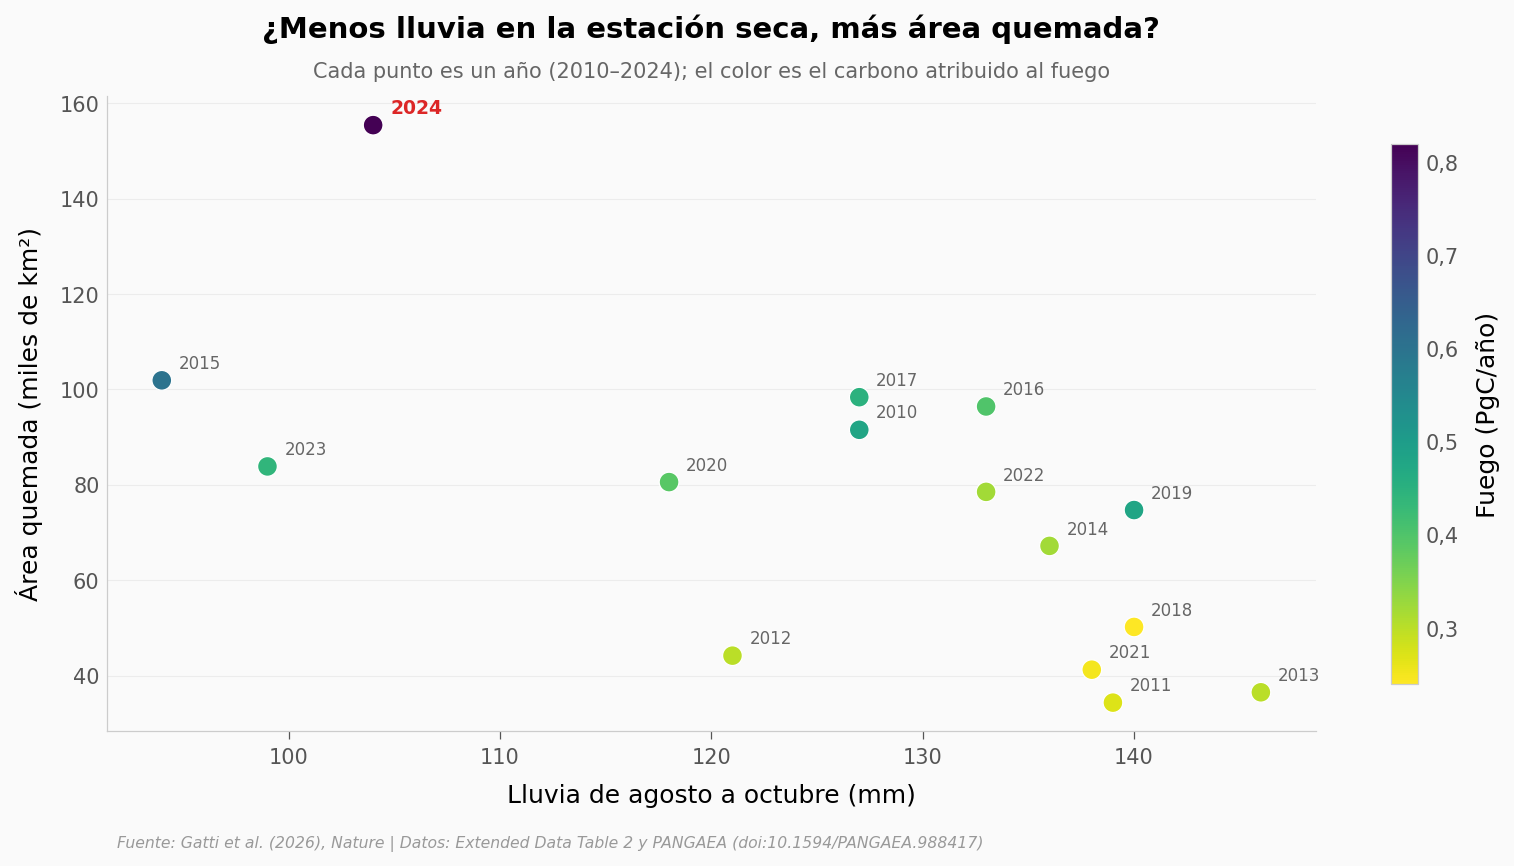

Correlaciones de Spearman entre años (n = 15):
  Área quemada ~ lluvia ago–oct    ρ = −0,72, p = 0,002
  Área quemada ~ T ago–oct         ρ = +0,69, p = 0,004
  Fuego ~ área quemada             ρ = +0,86, p < 0,001
  Fuego ~ focos de incendio        ρ = +0,74, p = 0,002
  Balance ~ área quemada           ρ = +0,51, p = 0,050
  Balance ~ deforestación anual    ρ = +0,24, p = 0,398
  Balance ~ lluvia anual           ρ = −0,46, p = 0,087


In [4]:
fig, ax = plt.subplots(figsize=(13, 5.5))
sc = ax.scatter(anual.p_aso_mm, anual.area_quemada_km2 / 1000, c=anual.fcf_pgc_yr, cmap='viridis_r',
                s=90, edgecolors='white', linewidths=0.6, zorder=5)
for _, f in anual.iterrows():
    destacado = f.anio == ANIO_DESTACADO
    ax.text(f.p_aso_mm + 0.8, f.area_quemada_km2 / 1000 + 2.5, str(int(f.anio)), fontsize=9 if destacado else 8,
            color=COLOR_ALERTA if destacado else '#666666', fontweight='bold' if destacado else 'normal')
cbar = plt.colorbar(sc, ax=ax, shrink=0.85)
cbar.set_label('Fuego (PgC/año)')
cbar.ax.yaxis.set_major_formatter(COMA)
ax.yaxis.set_major_formatter(COMA)
ax.set_xlabel('Lluvia de agosto a octubre (mm)')
ax.set_ylabel('Área quemada (miles de km²)')
ax.set_title('¿Menos lluvia en la estación seca, más área quemada?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'Cada punto es un año (2010–2024); el color es el carbono atribuido al fuego',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/lluvia_area_quemada.png', dpi=200, bbox_inches='tight')
plt.show()

pares = [('area_quemada_km2', 'p_aso_mm', 'Área quemada ~ lluvia ago–oct'),
         ('area_quemada_km2', 't_aso_c', 'Área quemada ~ T ago–oct'),
         ('fcf_pgc_yr', 'area_quemada_km2', 'Fuego ~ área quemada'),
         ('fcf_pgc_yr', 'focos_incendio', 'Fuego ~ focos de incendio'),
         ('tcf_pgc_yr', 'area_quemada_km2', 'Balance ~ área quemada'),
         ('tcf_pgc_yr', 'deforestacion_anual_km2', 'Balance ~ deforestación anual'),
         ('tcf_pgc_yr', 'p_anual_mm', 'Balance ~ lluvia anual')]
print(f'Correlaciones de Spearman entre años (n = {len(anual)}):')
for a, b, nombre in pares:
    r, p = stats.spearmanr(anual[a], anual[b])
    pr(f'  {nombre:<32} ρ = {r:+.2f}, {fp(p)}')

## ¿Se ve desde la avioneta?

Hasta aquí usamos los flujos anuales que calcularon los autores. Por debajo están los 948 perfiles de avión (cada perfil es una espiral de la avioneta, con sus frascos de aire llenados al descender desde unos 4.400 m hasta cerca del suelo), publicados en PANGAEA, un archivo abierto de datos ambientales. ¿Qué tan distinto es el aire de un año seco y cálido?

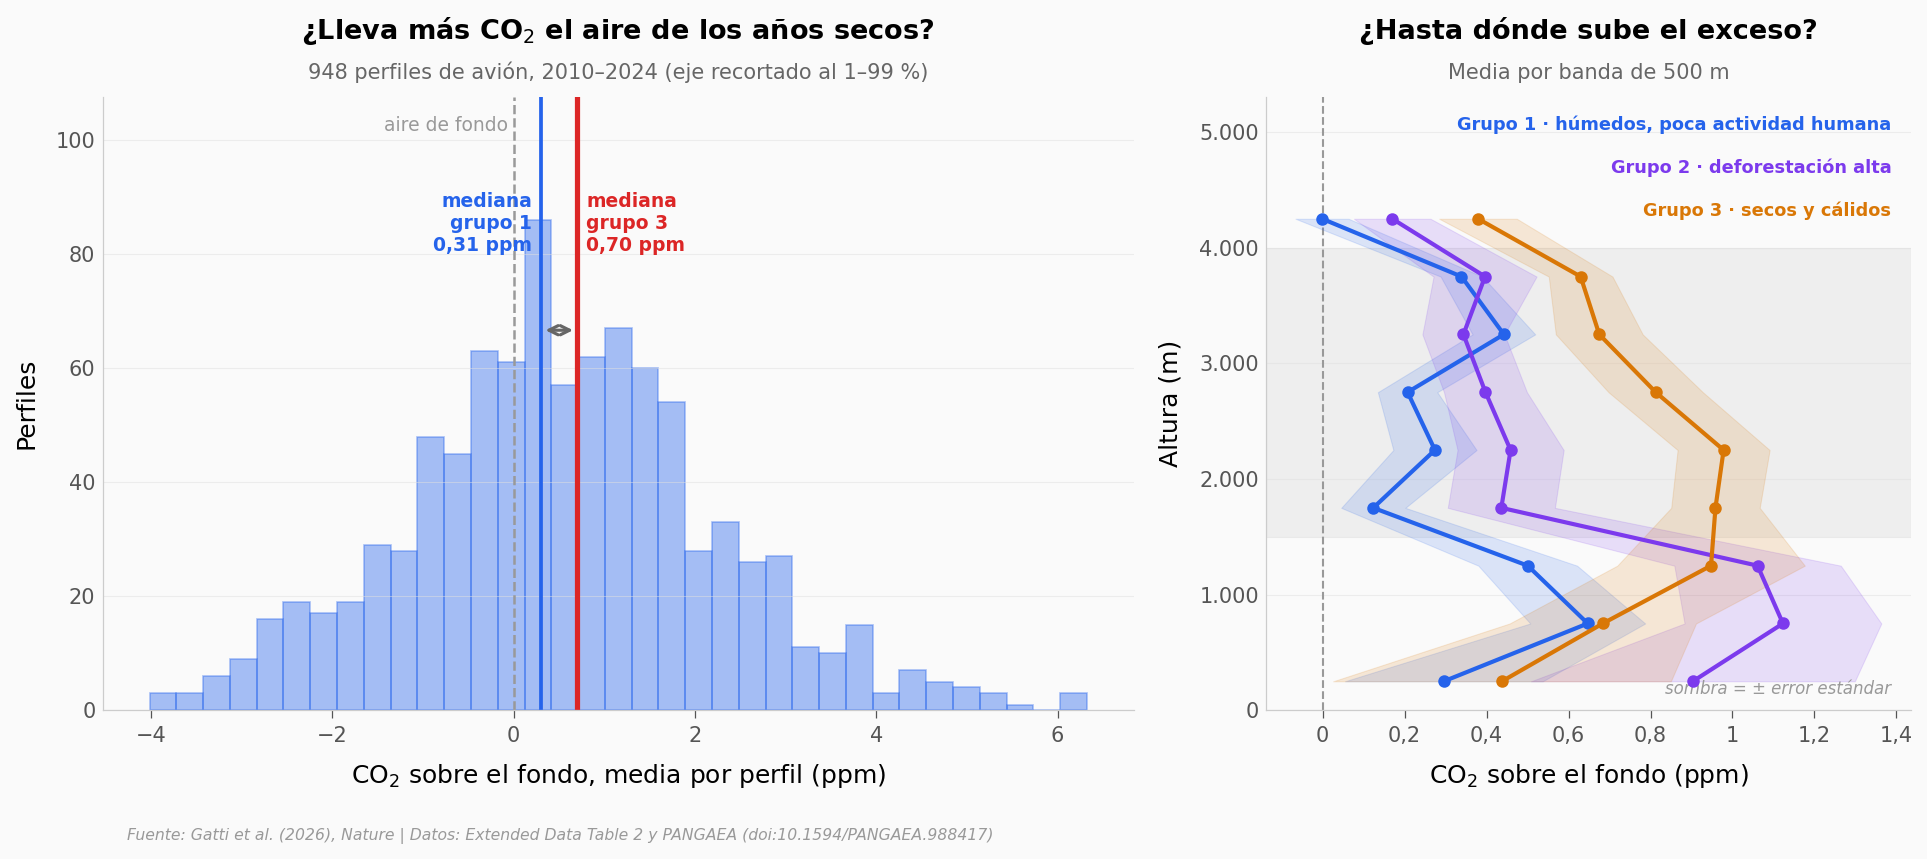

Perfiles con CO₂ por encima del fondo: 63,5 % de 948
Grupo 1: n = 422 perfiles, mediana 0,31 ppm (IQR −0,67 a 1,37)
Grupo 2: n = 266 perfiles, mediana 0,49 ppm (IQR −0,66 a 1,62)
Grupo 3: n = 260 perfiles, mediana 0,70 ppm (IQR −0,31 a 1,85)
Perfiles G1 vs G3: Mann-Whitney p = 0,004, d = 0,28
Perfiles G1 vs G2: Mann-Whitney p = 0,199, d = 0,15
Perfiles G2 vs G3: Mann-Whitney p = 0,144, d = 0,10
Promediando por año, G1 vs G3: Mann-Whitney p = 0,052, d = 1,54 (n = 6 y 5 años)
  ALF: G1 vs G3 por perfil p = 0,333, d = 0,25
  RBA: G1 vs G3 por perfil p = 0,101, d = 0,28
  SAN: G1 vs G3 por perfil p = 0,006, d = 0,45
  TTC: G1 vs G3 por perfil p = 0,098, d = 0,38
Media de las bandas entre 1.500 y 4.000 m: G1 0,28 · G2 0,41 · G3 0,81 ppm (G3 − G1 = +0,53 ppm)
Media de las bandas bajo 1.500 m: G1 0,48 · G2 1,03 · G3 0,69 ppm


In [5]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={'width_ratios': [1.6, 1]})
d = perfiles.dco2_media_ppm
lo, hi = np.percentile(d, [1, 99])
n, bins, _ = ax.hist(d, bins=35, range=(lo, hi), color=COLOR_DATOS, alpha=0.4, edgecolor=COLOR_DATOS, linewidth=0.8)
y_max = n.max() * 1.25
ax.set_ylim(0, y_max)
med = perfiles.groupby('grupo').dco2_media_ppm.median()
ax.axvline(0, color='#999999', lw=1.2, ls='--')
ax.text(0, y_max * 0.97, 'aire de fondo ', fontsize=9, color='#999999', ha='right', va='top')
ax.axvline(med[1], color=COLOR_GRUPO[1], lw=1.8)
ax.axvline(med[3], color=COLOR_ALERTA, lw=2.5)
ax.annotate('', xy=(med[3], y_max * 0.62), xytext=(med[1], y_max * 0.62),
            arrowprops=dict(arrowstyle='<->', color='#666666', lw=1.5))
ax.text(med[1] - 0.1, y_max * 0.75, 'mediana\ngrupo 1\n' + es(f'{med[1]:.2f}') + ' ppm', fontsize=9,
        color=COLOR_GRUPO[1], ha='right', fontweight='bold')
ax.text(med[3] + 0.1, y_max * 0.75, 'mediana\ngrupo 3\n' + es(f'{med[3]:.2f}') + ' ppm', fontsize=9,
        color=COLOR_ALERTA, ha='left', fontweight='bold')
ax.xaxis.set_major_formatter(COMA)
ax.set_xlabel('CO$_2$ sobre el fondo, media por perfil (ppm)')
ax.set_ylabel('Perfiles')
ax.set_title('¿Lleva más CO$_2$ el aire de los años secos?', fontsize=13, fontweight='bold', pad=28)
ax.text(0.5, 1.03, f'{len(perfiles):_} perfiles de avión, 2010–2024 (eje recortado al 1–99 %)'.replace('_', '.'),
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')

ax2.axhspan(BANDA_MIN, BANDA_MAX, color='#BBBBBB', alpha=0.18, zorder=1)
ax2.axvline(0, color='#999999', lw=1, ls='--')
for i, g in enumerate((1, 2, 3)):
    sub = vertical[vertical.grupo == g].sort_values('banda_m')
    ax2.plot(sub.dco2_media_ppm, sub.banda_m, marker='o', ms=5, color=COLOR_GRUPO[g], lw=2, zorder=4)
    ax2.fill_betweenx(sub.banda_m, sub.dco2_media_ppm - sub.dco2_sem, sub.dco2_media_ppm + sub.dco2_sem,
                      color=COLOR_GRUPO[g], alpha=0.15, zorder=3)
    ax2.text(0.97, 0.97 - 0.07 * i, NOMBRE_GRUPO[g].split('\n')[0] + ' · ' + NOMBRE_GRUPO[g].split('\n', 1)[1].replace('\n', ' '),
             transform=ax2.transAxes, fontsize=8.5, color=COLOR_GRUPO[g], fontweight='bold', ha='right', va='top')
ax2.text(0.97, 0.02, 'sombra = ± error estándar', transform=ax2.transAxes, fontsize=8, color='#999999',
         ha='right', va='bottom', style='italic')
ax2.set_ylim(0, 5300)
ax2.xaxis.set_major_formatter(COMA)
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:_.0f}'.replace('_', '.')))
ax2.set_xlabel('CO$_2$ sobre el fondo (ppm)')
ax2.set_ylabel('Altura (m)')
ax2.set_title('¿Hasta dónde sube el exceso?', fontsize=13, fontweight='bold', pad=28)
ax2.text(0.5, 1.03, 'Media por banda de 500 m', transform=ax2.transAxes, fontsize=10, color='#666666', ha='center')
plt.tight_layout()
fig.text(0.07, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/perfiles_avion.png', dpi=200, bbox_inches='tight')
plt.show()

pr(f'Perfiles con CO₂ por encima del fondo: {100 * (d > 0).mean():.1f} % de {len(d):_}')
for g in (1, 2, 3):
    s = perfiles[perfiles.grupo == g].dco2_media_ppm
    a, b = np.percentile(s, [25, 75])
    pr(f'Grupo {g}: n = {len(s)} perfiles, mediana {s.median():.2f} ppm (IQR {a:.2f} a {b:.2f})')
for a, b in [(1, 3), (1, 2), (2, 3)]:
    sa, sb = perfiles[perfiles.grupo == a].dco2_media_ppm, perfiles[perfiles.grupo == b].dco2_media_ppm
    p = stats.mannwhitneyu(sa, sb, alternative='two-sided').pvalue
    pr(f'Perfiles G{a} vs G{b}: Mann-Whitney {fp(p)}, d = {cohen_d(sa, sb):.2f}')
# El grupo se asigna por AÑO: los perfiles de un mismo año no son réplicas independientes
por_anio = perfiles.groupby(['year', 'grupo']).dco2_media_ppm.mean().reset_index()
a1, a3 = por_anio[por_anio.grupo == 1].dco2_media_ppm, por_anio[por_anio.grupo == 3].dco2_media_ppm
pr(f'Promediando por año, G1 vs G3: Mann-Whitney {fp(stats.mannwhitneyu(a1, a3, alternative="two-sided").pvalue)}, '
   f'd = {cohen_d(a1, a3):.2f} (n = {len(a1)} y {len(a3)} años)')
for r in sorted(perfiles.region.unique()):
    s1 = perfiles[(perfiles.region == r) & (perfiles.grupo == 1)].dco2_media_ppm
    s3 = perfiles[(perfiles.region == r) & (perfiles.grupo == 3)].dco2_media_ppm
    pr(f'  {r}: G1 vs G3 por perfil {fp(stats.mannwhitneyu(s1, s3, alternative="two-sided").pvalue)}, d = {cohen_d(s1, s3):.2f}')
franja = vertical[(vertical.banda_m > BANDA_MIN) & (vertical.banda_m < BANDA_MAX)].groupby('grupo').dco2_media_ppm.mean()
baja = vertical[vertical.banda_m < BANDA_MIN].groupby('grupo').dco2_media_ppm.mean()
pr(f'Media de las bandas entre {BANDA_MIN:_} y {BANDA_MAX:_} m: ' +
   ' · '.join(f'G{g} {franja[g]:.2f}' for g in franja.index) + f' ppm (G3 − G1 = {franja[3] - franja[1]:+.2f} ppm)')
pr(f'Media de las bandas bajo {BANDA_MIN:_} m: ' + ' · '.join(f'G{g} {baja[g]:.2f}' for g in baja.index) + ' ppm')

El aire de los años secos y cálidos tiende a llevar más CO₂, pero la diferencia es modesta vuelo a vuelo: mediana de 0,70 ppm en el grupo 3 frente a 0,31 en el grupo 1 (260 y 422 perfiles), con un tamaño de efecto pequeño (d = 0,28), porque los perfiles varían muchísimo entre sí. Ojo: el grupo se asigna por año, así que los perfiles de un mismo año no son independientes; promediando por año (5 y 6 años), la diferencia queda en el límite (p = 0,052). Donde más se separa es en altura: entre 1.500 y 4.000 m, el exceso medio del grupo 3 (0,81 ppm) supera en 0,53 ppm al del grupo 1 (0,28 ppm). Cerca del suelo, en cambio, la media más alta es la del grupo 2 (1,03 ppm frente a 0,69 y 0,48), aunque ahí las bandas son muy ruidosas. Es la misma forma que la Figura 2c del paper.

### Lo que los datos soportan

| Afirmación | ¿Soportada? | Detalle |
|------------|-------------|---------|
| La Amazonía fue fuente neta de carbono en 13 de 15 años | ✅ | El balance total queda por encima de cero en todos los años salvo 2011 (−0,01) y 2018 (−0,12). |
| El carbono atribuido al fuego supera al balance total medio: 0,40 frente a 0,32 PgC/año | ✅ | El bosque absorbe neto en 10 de 15 años y compensa una parte de la quema. El fuego se deduce del CO, con su propia incertidumbre. |
| Los años de deforestación alta y los años secos y cálidos emitieron más que los años húmedos | ⚠️ | +0,31 y +0,37 PgC/año frente al grupo 1 (d = 2,03 y 1,74; p = 0,019 y 0,030), pero con 6, 4 y 5 años, y el balance forma parte del propio agrupamiento: la diferencia es en parte circular. |
| Los años de deforestación alta y los años secos y cálidos no se distinguen en su balance | ⚠️ | Grupo 2 frente a grupo 3: p = 0,56, d = 0,29 (4 y 5 años). Con tan pocos años, no distinguirse no prueba que sean iguales, y el balance forma parte del agrupamiento. El texto del paper dice lo mismo («do not differ significantly»). |
| En los años con menos lluvia de agosto a octubre se quemó más área | ✅ | ρ = −0,72 (p = 0,002, n = 15 años). Es una asociación entre años, no un experimento. |
| Los autores concluyen que el sumidero amazónico se está debilitando | ⚠️ | Con 15 años, ni el balance (ρ = 0,22, p = 0,44) ni el intercambio del bosque (ρ = 0,16, p = 0,58) muestran tendencia con el año. La conclusión descansa en la comparación de grupos y en estudios previos. |
| En los años secos y cálidos el aire lleva más CO₂ sobre el fondo, sobre todo entre 1.500 y 4.000 m | ⚠️ | 948 perfiles de PANGAEA: 0,81 frente a 0,28 ppm en esa franja. Perfil a perfil, el efecto es pequeño (d = 0,28); promediando por año (5 frente a 6), p = 0,052, y solo 1 de las 4 regiones llega a p < 0,05 por separado. |

> **Limitaciones:** los flujos anuales están transcritos de una tabla del paper (Extended Data Table 2), no recalculados desde los frascos; el fuego se deduce del CO con un cociente CO₂:CO; los grupos salen de un *k-means* que incluye el propio balance; con 15 años, cualquier tendencia o correlación tiene poca potencia; las cuatro regiones se solapan y no se suman; los perfiles de PANGAEA son medias sin ponderar por región ni altura, así que muestran la forma del fenómeno, no el flujo del paper. Es un estudio observacional: los grupos describen asociaciones, no causas probadas.

## Ahora tú

1. **¿Qué región suelta más carbono y cuánta selva ha perdido?** La celda de abajo arma la tabla por región; cambia `REGION` en la configuración para ver en qué años su bosque emitió en vez de absorber.
2. **¿Cuánto pesa 2024 en el promedio?** Pista: `anual.query('anio != 2024').tcf_pgc_yr.mean()`.
3. **¿Va la deforestación del año de la mano con el balance?** Pista: `stats.spearmanr(anual.deforestacion_anual_km2, anual.tcf_pgc_yr)`. Compáralo con el área quemada.

In [6]:
# --- EXPERIMENTA AQUÍ ---
# ¿Qué región suelta más carbono, y cuánta selva ha perdido?
# Ojo: las regiones de influencia se solapan, así que NO se suman para dar la Amazonía.
reg = regiones.sort_values('anio').groupby('region').agg(
    balance=('tcf_pgc_yr', 'mean'), fuego=('fcf_pgc_yr', 'mean'), bosque=('nbe_pgc_yr', 'mean'),
    deforestado_2024=('deforestacion_acum_pct', 'last'),
    anios_bosque_emite=('nbe_pgc_yr', lambda s: int((s > 0).sum()))).sort_values('balance', ascending=False)
pr(f'{"Región":<8}{"Balance":>9}{"Fuego":>8}{"Bosque":>8}{"% deforestado 2024":>20}{"Años bosque emite":>19}')
for r, f in reg.iterrows():
    pr(f'{r:<8}{f.balance:>9.3f}{f.fuego:>8.3f}{(f.bosque if abs(f.bosque) >= 0.0005 else 0.0):>8.3f}{f.deforestado_2024:>20.1f}{int(f.anios_bosque_emite):>14} / 15')

sel = regiones[regiones.region == REGION].sort_values('anio')
emite = sel[sel.nbe_pgc_yr > 0].anio.tolist()
pr(f'\n{REGION}: el bosque emitió en vez de absorber en {len(emite)} de {len(sel)} años: {emite}')

Región    Balance   Fuego  Bosque  % deforestado 2024  Años bosque emite
SAN         0,457   0,456   0,000                38,0             6 / 15
ALF         0,370   0,201   0,169                33,5            13 / 15
RBA         0,055   0,159  −0,104                18,6             1 / 15
TTC         0,045   0,092  −0,047                10,4             6 / 15

ALF: el bosque emitió en vez de absorber en 13 de 15 años: [2011, 2012, 2013, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]


## Créditos

**Paper:** Gatti et al. (2026). *Amazon carbon emissions driven by human actions amplified by droughts*. Nature. DOI: [10.1038/s41586-026-11168-1](https://doi.org/10.1038/s41586-026-11168-1) · Acceso abierto (CC BY).

**Datos:** flujos anuales de la Amazonía y de sus cuatro regiones, transcritos de la Extended Data Table 2 del paper; perfiles de CO₂ de los vuelos en PANGAEA ([doi:10.1594/PANGAEA.988417](https://doi.org/10.1594/PANGAEA.988417)), resumidos como media de (observado − fondo) por perfil y por banda de altura, sin las muestras marcadas como atípicas.

**Repositorio:** [Ciencia-a-Mordiscos/lab](https://github.com/Ciencia-a-Mordiscos/lab)

## Fuentes

**Paper**: [Amazon carbon emissions driven by human actions amplified by droughts](https://doi.org/10.1038/s41586-026-11168-1)  
*Nature, 2026-10-21*

**Supplementary Material**: [Extended Data Table 2: Annual Amazon and sites carbon flux and parameters](https://www.nature.com/articles/s41586-026-11168-1/tables/2)  
*Nature, 2026-10-21*

**Supplementary Material**: [Extended Data Table 3: Carbon fluxes and studied parameters by groups](https://www.nature.com/articles/s41586-026-11168-1/tables/3)  
*Nature, 2026-10-21*

**Datos**: [CO2 Vertical Profiles on Four Sites over Amazon from 2010 to 2024](https://doi.org/10.1594/PANGAEA.988417)  
*PANGAEA, 2026-02-28*

*26 afirmaciones del notebook verificadas contra estas fuentes*